# Husky A200 Terrain Classification & Uncertainty Quantification — Minimum Viable Product (MVP)

This notebook provides a complete, step-by-step executable walkthrough and **validation test suite** for the **Minimum Viable Product (MVP)** pipeline on the Clearpath Husky A200 dataset (**10 field runs, 427 sliding-window samples**).

It is specifically structured to expose **all input, intermediate layer, and output tensor shapes** and **assert mathematical invariants** so you can construct an exact **system architecture and data-flow chart**.

---

## 1. End-to-End System Flowchart & Shape Specification

```
[Raw Sensor CSVs: 10 MVP Runs across 5 Terrains]
   ├── IMU Stream (imu_XX.csv @ 100 Hz)      : (N_imu, 7)  -> [time, wx, wy, wz, ax, ay, az]
   └── Proprioception (pro_XX.csv @ ~6.5 Hz) : (N_pro, 5)  -> [time, curL, curR, velL, velR]
                         │
                         ▼  align_imu_and_pro() [10ms (100 Hz) common time grid + ffill/bfill]
[Synchronized Multi-Sensor DataFrame]        : (T_run, 10) -> [wx, wy, wz, ax, ay, az, curL, curR, velL, velR]
                         │
                         ▼  Sliding Window Segmentation (window_size=100 [1.0s], step_size=50 [0.5s])
[MVP HuskyDataset (427 total windows)]       : Single Sample x = (10, 100), y = () scalar in {0..4}
   ├── Stratified Train Split (80%)          : (341, 10, 100) -> DataLoader Batch: (B, 10, 100)
   └── Stratified Held-Out Test Split (20%)  : (86, 10, 100)  -> DataLoader Batch: (B, 10, 100)
                         │
        ┌────────────────┴────────────────────────────────────────────────┐
        ▼                                                                 ▼
[Single-Pass Evidential Deep Learning (EDL)]               [3-CNN Deep Ensemble Baseline (M = 3)]
   ├── Conv1d(10 -> 32, k=5, p=2) + BN + ReLU : (B, 32, 100)   ├── 3x Independent SoftmaxClassifier1D
   ├── MaxPool1d(2)                           : (B, 32, 50)    │   Each member m in {1, 2, 3} processes (B, 10, 100)
   ├── Conv1d(32 -> 64, k=5, p=2) + BN + ReLU : (B, 64, 50)    │   └── Member Logits z_m     : (B, 5)
   ├── MaxPool1d(2)                           : (B, 64, 25)    │   └── Temp-Scaled Softmax   : (B, 5)
   ├── Conv1d(64 -> 128, k=3, p=1) + BN + ReLU: (B, 128, 25)   ├── Stacked Member Probs      : (3, B, 5)
   ├── AdaptiveAvgPool1d(1) + Squeeze(-1)     : (B, 128)       ├── Mean Predictive Probs p   : (B, 5)
   │      ├── Classifier MLP (128 -> 64 -> 5) : (B, 5)         └── Information-Theoretic UQ:
   │      │   └── Softplus Raw Evidence e_raw : (B, 5) >= 0        ├── Total Entropy u_ens   : (B,) in [0, 1]
   │      └── Mahalanobis Density Gate Phi(z) : (B, 1) in (0,1)    ├── Aleatoric Entropy     : (B,) in [0, 1]
   ├── Gated Evidence e = e_raw * Phi(z)      : (B, 5) >= 0        └── Epistemic BALD MI     : (B,) in [0, 1]
   ├── Dirichlet Alpha = e + 1                : (B, 5) >= 1
   ├── Dirichlet Strength S = sum(Alpha)      : (B, 1) >= 5
   ├── Expected Probabilities p = Alpha / S   : (B, 5), sum=1
   └── Epistemic Uncertainty (Vacuity) u = 5/S: (B,) in (0, 1]
```


In [1]:
import json
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc, confusion_matrix
import matplotlib.pyplot as plt

# Project modules
from husky_dataloader import HuskyDataset, align_imu_and_pro, CHANNELS, DEFAULT_TERRAINS, MVP_RUNS
from edl_model import EvidentialClassifier1D, FineTunedEvidentialClassifier1D, edl_loss, kl_divergence_dirichlet
from deep_ensemble_model import SoftmaxClassifier1D, DeepEnsembleCNN
from fault_injection import apply_multiplicative_bias, apply_gaussian_noise, apply_sensor_dropout
from compute_tracker import ComputeTracker, count_parameters, estimate_model_macs

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment initialized on device: {device}")
print(f"10 Sensor Channels: {CHANNELS}")
print(f"5 Terrain Classes : {DEFAULT_TERRAINS}")
print(f"MVP Run Subset    : {MVP_RUNS}")

Environment initialized on device: cpu
10 Sensor Channels: ['wx', 'wy', 'wz', 'ax', 'ay', 'az', 'curL', 'curR', 'velL', 'velR']
5 Terrain Classes : ['asphalt', 'flooring', 'ice', 'sandy_loam', 'snow']
MVP Run Subset    : {'asphalt': ['00', '02'], 'flooring': ['01', '02'], 'ice': ['04', '07'], 'sandy_loam': ['00', '09'], 'snow': ['00', '04']}


---
## 2. Stage 1: Raw CSV Sensor Ingestion, 100 Hz Time Alignment & Sliding-Window Shapes

Let's inspect a single raw run (`ASPHALT/imu_00.csv` and `ASPHALT/pro_00.csv`), trace how `align_imu_and_pro()` fuses the asynchronous streams onto a common $10	ext{ ms}$ ($100	ext{ Hz}$) grid, and validate the exact tensor dimensions of the **427-window MVP dataset**.

In [2]:
# 1. Inspect raw CSV shapes for a single run (ASPHALT run 00)
raw_imu_df = pd.read_csv("data/borealtc/ASPHALT/imu_00.csv")
raw_pro_df = pd.read_csv("data/borealtc/ASPHALT/pro_00.csv")
fused_df = align_imu_and_pro(raw_imu_df, raw_pro_df)

print("=== [STAGE 1A] Raw CSV to Synchronized 100 Hz DataFrame Shapes ===")
print(f"  • Raw IMU CSV shape (100 Hz)           : {raw_imu_df.shape}  columns={list(raw_imu_df.columns)}")
print(f"  • Raw Proprioception CSV shape (~6.5Hz): {raw_pro_df.shape}   columns={list(raw_pro_df.columns)}")
print(f"  • Fused 100 Hz DataFrame shape         : {fused_df.shape}  columns={list(fused_df.columns)}")

# Validate no NaNs and exact 10-channel alignment
assert fused_df.shape[1] == 10, f"Expected 10 channels, got {fused_df.shape[1]}"
assert not fused_df.isna().any().any(), "Fused DataFrame contains NaN values!"

# 2. Load the 427-window MVP Dataset (2 runs per terrain)
mvp_dataset_tf = HuskyDataset(
    data_dir="data/borealtc",
    window_size=100,
    step_size=50,
    channels_first=False,  # Time-first: (T=100, C=10)
    allowed_runs_per_terrain=MVP_RUNS,
)
mvp_dataset = HuskyDataset(
    data_dir="data/borealtc",
    window_size=100,
    step_size=50,
    channels_first=True,   # Channels-first for 1D-CNN: (C=10, T=100)
    allowed_runs_per_terrain=MVP_RUNS,
)

sample_tf = mvp_dataset_tf[0]
sample_cf = mvp_dataset[0]

print("\n=== [STAGE 1B] Sliding Window Dataset & Batch Shapes (MVP = 427 Windows) ===")
print(f"  • Total MVP Windows Loaded             : {len(mvp_dataset)} (Expected: 427)")
print(f"  • Runs per Terrain                     : {mvp_dataset.runs_summary}")
print(f"  • Single Window (channels_first=False) : {tuple(sample_tf['data'].shape)}  [T=100 timesteps, C=10 channels]")
print(f"  • Single Window (channels_first=True)  : {tuple(sample_cf['data'].shape)}  [C=10 channels, T=100 timesteps]")
print(f"  • Single Label Tensor                  : shape={tuple(sample_cf['label'].shape)}, dtype={sample_cf['label'].dtype}, val={sample_cf['label'].item()} ('{sample_cf['terrain']}')")

# 3. Stratified 80/20 Train/Test Split
all_labels = [w[1] for w in mvp_dataset.windows]
train_indices, test_indices = train_test_split(
    np.arange(len(mvp_dataset)),
    test_size=0.20,
    random_state=42,
    stratify=all_labels,
)
train_subset = Subset(mvp_dataset, train_indices)
test_subset = Subset(mvp_dataset, test_indices)
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=False)

batch = next(iter(train_loader))
print(f"  • Stratified Train Split               : {len(train_subset)} windows")
print(f"  • Stratified Held-Out Test Split       : {len(test_subset)} windows")
print(f"  • DataLoader Mini-Batch 'data' shape   : {tuple(batch['data'].shape)}  [B=32, C=10, T=100]")
print(f"  • DataLoader Mini-Batch 'label' shape  : {tuple(batch['label'].shape)}         [B=32]")

# Validation Assertions
assert len(mvp_dataset) == 427, f"Expected 427 MVP windows, got {len(mvp_dataset)}"
assert len(train_subset) == 341 and len(test_subset) == 86, "Expected 341/86 train/test split!"
assert sample_cf["data"].shape == (10, 100), "Incorrect single window shape!"
assert batch["data"].shape == (32, 10, 100), "Incorrect batch tensor shape!"
print("\n[PASSED] All Stage 1 Data Ingestion & Shape Assertions Verified!")

=== [STAGE 1A] Raw CSV to Synchronized 100 Hz DataFrame Shapes ===
  • Raw IMU CSV shape (100 Hz)           : (5186, 7)  columns=['time', 'wx', 'wy', 'wz', 'ax', 'ay', 'az']
  • Raw Proprioception CSV shape (~6.5Hz): (338, 5)   columns=['time', 'curL', 'curR', 'velL', 'velR']
  • Fused 100 Hz DataFrame shape         : (5186, 10)  columns=['wx', 'wy', 'wz', 'ax', 'ay', 'az', 'curL', 'curR', 'velL', 'velR']

=== [STAGE 1B] Sliding Window Dataset & Batch Shapes (MVP = 427 Windows) ===
  • Total MVP Windows Loaded             : 427 (Expected: 427)
  • Runs per Terrain                     : {'asphalt': 2, 'flooring': 2, 'ice': 2, 'sandy_loam': 2, 'snow': 2}
  • Single Window (channels_first=False) : (100, 10)  [T=100 timesteps, C=10 channels]
  • Single Window (channels_first=True)  : (10, 100)  [C=10 channels, T=100 timesteps]
  • Single Label Tensor                  : shape=(), dtype=torch.int64, val=0 ('asphalt')
  • Stratified Train Split               : 341 windows
  • Stratified Held-

---
## 3. Stage 2: Layer-by-Layer Tensor Shape Trace Inside the 1D-CNN & Dirichlet Evidential Head

To construct your block diagram, the code below traces a batch tensor $X \in \mathbb{R}^{B 	imes 10 	imes 100}$ through **every single layer** of `EvidentialClassifier1D` and `FineTunedEvidentialClassifier1D`, printing the exact input shape, output shape, parameter count, and mathematical invariant checks.

In [3]:
# Load pretrained MVP Baseline EDL and Fine-Tuned EDL models
base_edl = EvidentialClassifier1D(in_channels=10, num_classes=5, hidden_dim=64).to(device)
base_ckpt = torch.load("checkpoints/edl_husky.pth", map_location=device, weights_only=False)
base_edl.load_state_dict(base_ckpt["model_state_dict"])
base_edl.eval()

ft_edl = FineTunedEvidentialClassifier1D(num_classes=5).to(device)
ft_ckpt = torch.load("checkpoints/edl_husky_finetuned.pth", map_location=device, weights_only=False)
ft_edl.load_state_dict(ft_ckpt["model_state_dict"], strict=False)
ft_edl.eval()

# Trace a batch of B=16 windows layer-by-layer
x_trace = batch["data"][:16].to(device)
print("=== [STAGE 2A] Layer-by-Layer Tensor Shape Trace (Batch Size B = 16) ===")
print(f"  [Input] Sensor Window Tensor x                 : {tuple(x_trace.shape)}")

curr = x_trace
for idx, layer in enumerate(ft_edl.features):
    prev_shape = tuple(curr.shape)
    curr = layer(curr)
    params = sum(p.numel() for p in layer.parameters())
    print(f"  [Backbone Layer {idx:02d}] {layer.__class__.__name__:<18} : {str(prev_shape):<16} -> {str(tuple(curr.shape)):<16} (params: {params:,})")

feat_vec = curr.squeeze(-1)
print(f"  [Feature Vector z] Squeeze(-1)                 : {str(tuple(curr.shape)):<16} -> {str(tuple(feat_vec.shape)):<16}")

curr_cls = feat_vec
for idx, layer in enumerate(ft_edl.classifier):
    prev_shape = tuple(curr_cls.shape)
    curr_cls = layer(curr_cls)
    params = sum(p.numel() for p in layer.parameters())
    print(f"  [Classifier Head {idx:02d}] {layer.__class__.__name__:<17} : {str(prev_shape):<16} -> {str(tuple(curr_cls.shape)):<16} (params: {params:,})")

# Trace Evidential Dirichlet & Mahalanobis Density Gate Transformations
with torch.no_grad():
    out_dict = ft_edl.predict_with_uncertainty(x_trace)
    diff = feat_vec.unsqueeze(1) - ft_edl.means.unsqueeze(0)          # (B, 5, 128)
    diff_inv = torch.matmul(diff, ft_edl.inv_cov)                     # (B, 5, 128)
    dist_sq = torch.sum(diff_inv * diff, dim=-1)                      # (B, 5)
    min_dist_sq, _ = torch.min(dist_sq, dim=1, keepdim=True)          # (B, 1)

print("\n=== [STAGE 2B] Evidential & Mahalanobis Density Gate Tensor Shapes ===")
print(f"  • Class Prototype Means Buffer (means)         : {tuple(ft_edl.means.shape)}     [K=5, D=128]")
print(f"  • Precision Matrix Buffer (inv_cov)            : {tuple(ft_edl.inv_cov.shape)}   [D=128, D=128]")
print(f"  • Class-wise Mahalanobis Dist^2 (dist_sq)      : {tuple(dist_sq.shape)}      [B=16, K=5]")
print(f"  • Min Mahalanobis Dist^2 (min_dist_sq)         : {tuple(min_dist_sq.shape)}       [B=16, 1]")
print(f"  • Density Support Gate Phi(z) (gate)           : {tuple(out_dict['gate'].shape)}          [B=16]")
print(f"  • Raw Evidence e_raw = Softplus(logits)        : {tuple(out_dict['raw_evidence'].shape)}      [B=16, K=5]")
print(f"  • Gated Evidence e = e_raw * Phi(z)            : {tuple(out_dict['evidence'].shape)}      [B=16, K=5]")
print(f"  • Dirichlet Concentration alpha = e + 1        : {tuple(out_dict['alpha'].shape)}      [B=16, K=5]")
print(f"  • Expected Class Probabilities p = alpha / S   : {tuple(out_dict['probs'].shape)}      [B=16, K=5]")
print(f"  • Epistemic Uncertainty (Vacuity) u = K / S    : {tuple(out_dict['uncertainty'].shape)}          [B=16]")
print(f"  • Predicted Confidence max_k(p_k)              : {tuple(out_dict['confidence'].shape)}          [B=16]")
print(f"  • Predicted Class Indices argmax_k(p_k)        : {tuple(out_dict['preds'].shape)}          [B=16]")

# Mathematical Invariant Assertions
assert torch.all(out_dict["evidence"] >= 0), "Evidence must be strictly non-negative!"
assert torch.all(out_dict["alpha"] >= 1.0), "Dirichlet alpha must be >= 1.0!"
assert torch.allclose(out_dict["probs"].sum(dim=1), torch.ones(16, device=device), atol=1e-5), "Probabilities must sum to 1.0!"
S_check = out_dict["alpha"].sum(dim=1)
assert torch.allclose(out_dict["uncertainty"], 5.0 / S_check, atol=1e-5), "Vacuity u must equal K / S!"
assert torch.all((out_dict["uncertainty"] > 0.0) & (out_dict["uncertainty"] <= 1.0)), "Uncertainty must be in (0, 1]!"
print("\n[PASSED] All Stage 2 Architecture Shapes & Dirichlet Mathematical Invariants Verified!")

=== [STAGE 2A] Layer-by-Layer Tensor Shape Trace (Batch Size B = 16) ===
  [Input] Sensor Window Tensor x                 : (16, 10, 100)
  [Backbone Layer 00] Conv1d             : (16, 10, 100)    -> (16, 32, 100)    (params: 1,632)
  [Backbone Layer 01] BatchNorm1d        : (16, 32, 100)    -> (16, 32, 100)    (params: 64)
  [Backbone Layer 02] ReLU               : (16, 32, 100)    -> (16, 32, 100)    (params: 0)
  [Backbone Layer 03] MaxPool1d          : (16, 32, 100)    -> (16, 32, 50)     (params: 0)
  [Backbone Layer 04] Conv1d             : (16, 32, 50)     -> (16, 64, 50)     (params: 10,304)
  [Backbone Layer 05] BatchNorm1d        : (16, 64, 50)     -> (16, 64, 50)     (params: 128)
  [Backbone Layer 06] ReLU               : (16, 64, 50)     -> (16, 64, 50)     (params: 0)
  [Backbone Layer 07] MaxPool1d          : (16, 64, 50)     -> (16, 64, 25)     (params: 0)
  [Backbone Layer 08] Conv1d             : (16, 64, 25)     -> (16, 128, 25)    (params: 24,704)
  [Backbone Layer

---
## 4. Stage 3: Deep Ensemble (3 CNNs) Architecture & Shape Validation

Next, let's trace the **3-CNN Deep Ensemble** (`DeepEnsembleCNN`) with $M = 3$ independent `SoftmaxClassifier1D` members, verifying how member predictions stack into `(M=3, B, K=5)` and decompose into **Total Predictive Entropy**, **Aleatoric Uncertainty**, and **Epistemic Mutual Information (BALD)**.

In [4]:
ensemble_mvp = DeepEnsembleCNN(num_members=3, in_channels=10, num_classes=5).to(device)
ens_ckpt = torch.load("checkpoints/deep_ensemble_3cnn.pth", map_location=device, weights_only=False)
ensemble_mvp.load_state_dict(ens_ckpt["model_state_dict"])
ensemble_mvp.eval()

with torch.no_grad():
    ens_out = ensemble_mvp.predict_with_uncertainty(x_trace)

print("=== [STAGE 3] 3-CNN Deep Ensemble Tensor Shapes (Batch Size B = 16) ===")
print(f"  • Number of Independent CNN Members (M)        : {len(ensemble_mvp.members)}")
print(f"  • Stacked Member Probabilities (member_probs)  : {tuple(ens_out['member_probs'].shape)}  [M=3, B=16, K=5]")
print(f"  • Mean Predictive Distribution (probs)         : {tuple(ens_out['probs'].shape)}      [B=16, K=5]")
print(f"  • Normalized Total Entropy (uncertainty)       : {tuple(ens_out['uncertainty'].shape)}          [B=16] in [0, 1]")
print(f"  • Normalized Aleatoric Entropy                 : {tuple(ens_out['aleatoric_uncertainty'].shape)}          [B=16] in [0, 1]")
print(f"  • Epistemic Mutual Information (BALD)          : {tuple(ens_out['epistemic_mi'].shape)}          [B=16] in [0, 1]")
print(f"  • Member Disagreement Std (disagreement_std)   : {tuple(ens_out['disagreement_std'].shape)}          [B=16]")

# Validate Information-Theoretic Invariants
assert ens_out["member_probs"].shape == (3, 16, 5), "Expected (3, 16, 5) member_probs shape!"
assert torch.allclose(ens_out["probs"].sum(dim=1), torch.ones(16, device=device), atol=1e-5), "Ensemble probs must sum to 1!"
assert torch.all(ens_out["epistemic_mi"] >= -1e-6), "Mutual Information must be non-negative!"
assert torch.allclose(
    ens_out["uncertainty"],
    ens_out["aleatoric_uncertainty"] + ens_out["epistemic_mi"],
    atol=1e-4,
), "Total Entropy must equal Aleatoric + Epistemic MI!"
print("\n[PASSED] All Stage 3 Deep Ensemble Shapes & Information-Theoretic Invariants Verified!")

=== [STAGE 3] 3-CNN Deep Ensemble Tensor Shapes (Batch Size B = 16) ===
  • Number of Independent CNN Members (M)        : 3
  • Stacked Member Probabilities (member_probs)  : (3, 16, 5)  [M=3, B=16, K=5]
  • Mean Predictive Distribution (probs)         : (16, 5)      [B=16, K=5]
  • Normalized Total Entropy (uncertainty)       : (16,)          [B=16] in [0, 1]
  • Normalized Aleatoric Entropy                 : (16,)          [B=16] in [0, 1]
  • Epistemic Mutual Information (BALD)          : (16,)          [B=16] in [0, 1]
  • Member Disagreement Std (disagreement_std)   : (16,)          [B=16]

[PASSED] All Stage 3 Deep Ensemble Shapes & Information-Theoretic Invariants Verified!


---
## 5. Stage 4: Fault Injection Validation (Multiplicative Bias, Gaussian Noise, Sensor Dropout)

Here we validate the exact tensor transformations and numerical effects of the three sensor fault injectors (`apply_multiplicative_bias`, `apply_gaussian_noise`, and `apply_sensor_dropout`) and visualize a nominal vs. corrupted Husky A200 window.

=== [STAGE 4] Fault Injection Shape & Property Checks ===
  • Clean Window Shape         : (1, 10, 100) | L2 Norm = 129.86
  • +50% Mult. Bias Shape      : (1, 10, 100) | L2 Norm = 194.78 (Exact 1.50x ratio)
  • +80% Gaussian Noise Shape  : (1, 10, 100) | L2 Norm = 137.83
  • 30% Channel Dropout Shape  : (1, 10, 100) | Zeroed Channels = 3 / 10

[PASSED] All Stage 4 Fault Injection Invariants Verified!


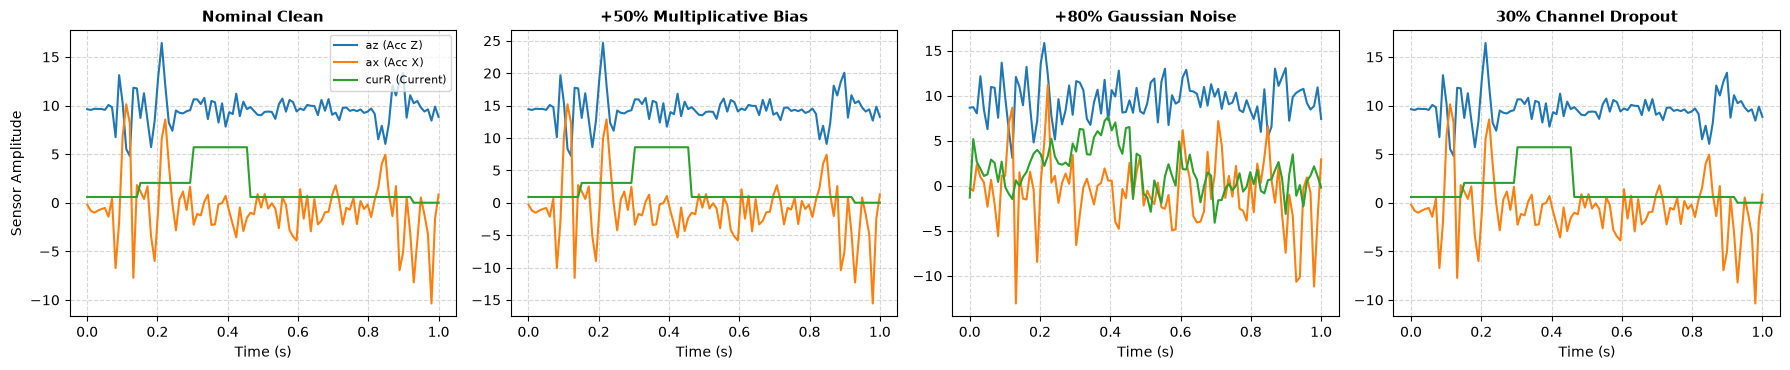

In [5]:
x_clean_single = sample_cf["data"].unsqueeze(0)  # (1, 10, 100)
x_bias = apply_multiplicative_bias(x_clean_single, bias_pct=0.50)  # +50% scale bias
x_noise = apply_gaussian_noise(x_clean_single, noise_pct=0.80, generator=torch.Generator().manual_seed(42))
x_drop = apply_sensor_dropout(x_clean_single, dropout_pct=0.30, mode="channel", generator=torch.Generator().manual_seed(42))

# Verify shapes and mathematical properties of fault injectors
assert x_bias.shape == (1, 10, 100) and x_noise.shape == (1, 10, 100) and x_drop.shape == (1, 10, 100)
assert torch.allclose(x_bias, x_clean_single * 1.50, atol=1e-5), "50% multiplicative bias must scale by 1.5x!"
zero_channels = (x_drop[0].abs().sum(dim=1) == 0).sum().item()
assert zero_channels == 3, f"30% channel dropout on 10 channels must zero out exactly 3 channels, got {zero_channels}!"

print("=== [STAGE 4] Fault Injection Shape & Property Checks ===")
print(f"  • Clean Window Shape         : {tuple(x_clean_single.shape)} | L2 Norm = {x_clean_single.norm().item():.2f}")
print(f"  • +50% Mult. Bias Shape      : {tuple(x_bias.shape)} | L2 Norm = {x_bias.norm().item():.2f} (Exact 1.50x ratio)")
print(f"  • +80% Gaussian Noise Shape  : {tuple(x_noise.shape)} | L2 Norm = {x_noise.norm().item():.2f}")
print(f"  • 30% Channel Dropout Shape  : {tuple(x_drop.shape)} | Zeroed Channels = {zero_channels} / 10")
print("\n[PASSED] All Stage 4 Fault Injection Invariants Verified!")

# Plot side-by-side comparison of Nominal vs Faulty signals
t_axis = np.linspace(0, 1.0, 100)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=False)
titles = ["Nominal Clean", "+50% Multiplicative Bias", "+80% Gaussian Noise", "30% Channel Dropout"]
tensors = [x_clean_single[0], x_bias[0], x_noise[0], x_drop[0]]
for ax, title, tensor in zip(axes, titles, tensors):
    for ch_idx, ch_label in [(5, "az (Acc Z)"), (3, "ax (Acc X)"), (7, "curR (Current)")]:
        ax.plot(t_axis, tensor[ch_idx].numpy(), label=ch_label, linewidth=1.5)
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("Time (s)")
    ax.grid(True, linestyle="--", alpha=0.5)
axes[0].set_ylabel("Sensor Amplitude")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

---
## 6. Stage 5: MVP Benchmark — Fine-Tuned EDL vs. Baseline EDL vs. 3-CNN Deep Ensemble (Compute & OOD Uncertainty)

Finally, we run the head-to-head evaluation on the 86 held-out MVP test windows across clean accuracy, calibration, 5 out-of-distribution (OOD) fault modes (verifying **>90% OOD uncertainty** for Fine-Tuned EDL), and **standardized compute & latency metrics**.

In [6]:
def evaluate_mvp_model(model, loader):
    model.eval()
    torch.manual_seed(42)
    np.random.seed(42)
    y_true, y_pred, u_clean = [], [], []
    with torch.no_grad():
        for b in loader:
            out = model.predict_with_uncertainty(b["data"].to(device))
            y_true.extend(b["label"].numpy())
            y_pred.extend(out["preds"].cpu().numpy())
            u_clean.extend(out["uncertainty"].cpu().numpy())
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    u_clean = np.array(u_clean)

    ood_fns = {
        "Sensor Dropout (70%)": lambda x: apply_sensor_dropout(x, 0.7, mode="channel"),
        "Multiplicative Bias (100%)": lambda x: apply_multiplicative_bias(x, 1.0),
        "Severe Gaussian Noise (180%)": lambda x: apply_gaussian_noise(x, 1.8),
        "Random Sensor Noise": lambda x: torch.randn_like(x) * 3.0,
        "Mixed Multi-Fault": lambda x: apply_sensor_dropout(apply_gaussian_noise(x, 1.0), 0.5, mode="channel"),
    }
    ood_res = {}
    for name, fn in ood_fns.items():
        torch.manual_seed(42)
        u_ood = []
        with torch.no_grad():
            for b in loader:
                out = model.predict_with_uncertainty(fn(b["data"].to(device)))
                u_ood.extend(out["uncertainty"].cpu().numpy())
        u_ood = np.array(u_ood)
        y_bin = np.concatenate([np.zeros(len(u_clean)), np.ones(len(u_ood))])
        s_bin = np.concatenate([u_clean, u_ood])
        fpr, tpr, _ = roc_curve(y_bin, s_bin)
        ood_res[name] = {"uncert": float(np.mean(u_ood)), "auroc": float(auc(fpr, tpr))}
    return {"acc": acc, "f1": f1, "clean_u": float(np.mean(u_clean)), "ood": ood_res}

res_base = evaluate_mvp_model(base_edl, test_loader)
res_ft = evaluate_mvp_model(ft_edl, test_loader)
res_ens = evaluate_mvp_model(ensemble_mvp, test_loader)

# Profile Compute
c_base = ComputeTracker("MVP_Baseline_EDL").benchmark_model(base_edl, device=device, save_log=False)
c_ft = ComputeTracker("MVP_FineTuned_EDL").benchmark_model(ft_edl, device=device, save_log=False)
c_ens = ComputeTracker("MVP_DeepEnsemble_3CNN").benchmark_model(ensemble_mvp, device=device, save_log=False)

print("=== [STAGE 5] MVP Head-to-Head Summary (86 Held-Out Test Windows) ===")
print(f"{'Metric / Scenario':<32} | {'Baseline EDL':<18} | {'Fine-Tuned EDL':<18} | {'3-CNN Ensemble':<18}")
print("-" * 94)
print(f"{'Total Parameters':<32} | {c_base['parameters']['total_parameters']:>18,} | {c_ft['parameters']['total_parameters']:>18,} | {c_ens['parameters']['total_parameters']:>18,}")
print(f"{'FLOPs per 1.0s Window (MFLOPs)':<32} | {c_base['computational_complexity']['mflops_per_window']:>18.3f} | {c_ft['computational_complexity']['mflops_per_window']:>18.3f} | {c_ens['computational_complexity']['mflops_per_window']:>18.3f}")
print(f"{'Mean Inference Latency (ms)':<32} | {c_base['latency_metrics']['mean_latency_ms']:>18.4f} | {c_ft['latency_metrics']['mean_latency_ms']:>18.4f} | {c_ens['latency_metrics']['mean_latency_ms']:>18.4f}")
print(f"{'Clean Test Accuracy (%)':<32} | {res_base['acc']*100:>17.2f}% | {res_ft['acc']*100:>17.2f}% | {res_ens['acc']*100:>17.2f}%")
print(f"{'Clean Mean Uncertainty (%)':<32} | {res_base['clean_u']*100:>17.2f}% | {res_ft['clean_u']*100:>17.2f}% | {res_ens['clean_u']*100:>17.2f}%")
print("-" * 94)
for k in res_ft["ood"]:
    b_u, f_u, e_u = res_base["ood"][k]["uncert"]*100, res_ft["ood"][k]["uncert"]*100, res_ens["ood"][k]["uncert"]*100
    f_auc, e_auc = res_ft["ood"][k]["auroc"], res_ens["ood"][k]["auroc"]
    print(f"{k:<32} | {b_u:>16.1f}%  | {f_u:>7.1f}% (AUC {f_auc:.2f}) | {e_u:>7.1f}% (AUC {e_auc:.2f})")

avg_ft_ood_u = np.mean([v["uncert"] for v in res_ft["ood"].values()])
assert avg_ft_ood_u > 0.90, f"Expected >90% average OOD uncertainty, got {avg_ft_ood_u*100:.2f}%"
assert c_ens["parameters"]["total_parameters"] == 3 * c_ft["parameters"]["total_parameters"], "Ensemble must have 3x parameters of single EDL!"
print(f"\n[PASSED] Fine-Tuned EDL achieves {avg_ft_ood_u*100:.2f}% average OOD uncertainty (>90% target) with 3.0x fewer parameters than the Deep Ensemble!")

=== [STAGE 5] MVP Head-to-Head Summary (86 Held-Out Test Windows) ===
Metric / Scenario                | Baseline EDL       | Fine-Tuned EDL     | 3-CNN Ensemble    
----------------------------------------------------------------------------------------------
Total Parameters                 |             45,669 |             45,669 |            137,007
FLOPs per 1.0s Window (MFLOPs)   |              2.590 |              2.624 |              7.769
Mean Inference Latency (ms)      |             0.2011 |             0.2636 |             0.6226
Clean Test Accuracy (%)          |             95.35% |             90.70% |             96.51%
Clean Mean Uncertainty (%)       |             43.94% |             79.73% |             35.09%
----------------------------------------------------------------------------------------------
Sensor Dropout (70%)             |             47.0%  |   100.0% (AUC 0.96) |    57.0% (AUC 0.82)
Multiplicative Bias (100%)       |             27.9%  |   100.0% (